# OCR Lens

The OCR lens reads the scene as words, without a text query. For every mesh vertex it stores
the words the surface most likely shows, each with a probability. It runs a vision-language model
(LLaVA-1.6) on each keyframe and turns each image patch into word probabilities. The model
weights must already be in the local Hugging Face cache.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
import torch
import transformers
import zarr

from collab_splats.geometry.transforms import invert_poses
from collab_splats.pointcloud import PointcloudResult
from collab_splats.reconstructor import store_rows
from collab_splats.semantics import FeatureAutoencoder
from collab_splats.semantics.features.ocr_lens import (
    load_decoder,
    load_processor,
    word_probabilities,
    word_vocabulary,
)
from collab_splats.utils.visualization import apply_view, camera_view

# Use the cached model weights only; set before the model libraries load
os.environ["HF_HUB_OFFLINE"] = "1"
transformers.logging.set_verbosity_error()

%run ../tutorial.py

scene = tutorial_scene("preproc", "pointcloud", "mesh", "semantics", extractor="ocr_lens")

# Image panels without axes
BARE = {"frame_on": False, "xticks": [], "yticks": []}

## 1. Top words on the mesh

The stage stores, per vertex, the 64 most likely words and their probabilities. A vertex no
keyframe saw has all-zero probabilities.

The ten most common best words across the mesh:

In [2]:
store = zarr.open(str(scene.lifted_stores["ocr_lens"]), mode="r")
word_ids = np.asarray(store["vertex_word_ids"])
word_probs = np.asarray(store["vertex_word_probs"], dtype=np.float32)
words = list(store.attrs["words"])

observed = word_probs[:, 0] > 0
print(f"{observed.mean():.1%} of {len(observed):,} vertices observed, {len(words):,} words\n")

# Count each observed vertex's best word
counts = np.bincount(word_ids[observed, 0], minlength=len(words))

for word_id in np.argsort(counts)[::-1][:10]:
    print(f"{words[word_id]:15s} {counts[word_id]:>8,} vertices")

99.5% of 231,065 vertices observed, 3,512 words

tree             104,137 vertices
forest            31,176 vertices
log               19,401 vertices
grass             11,247 vertices
leave             10,093 vertices
branch             4,152 vertices
leaf               3,715 vertices
road               3,344 vertices
ground             3,050 vertices
wood               2,982 vertices


## 2. Single patches

The stage keeps every keyframe's patch states in compressed form. Decoding them needs only the
model's last layers (`load_decoder`, about 260 MB), not the full 7B model.

Decode one patch on each of two keyframes, cut to the words the viewer shows: words in some
vertex's top ten, rescaled to sum to 1.

In [3]:
codes_path = scene.semantics_cache_dir / "ocr_lens_codes.zarr"
codes = zarr.open(str(codes_path), mode="r")["features"]
cloud = PointcloudResult.load_zarr(scene.pointcloud_zarr, load_world_points=False)
rows = store_rows(scene.images_dir, cloud.image_paths)

model_id = "llava-hf/llava-v1.6-vicuna-7b-hf"
ae = FeatureAutoencoder.load(codes_path / "autoencoder.pt").to("cuda")
decoder = load_decoder(model_id)
vocab = word_vocabulary(load_processor(model_id).tokenizer)

# Scene words: every word in some observed vertex's top ten, as in the viewer
is_term = np.zeros(len(words), dtype=bool)
is_term[np.unique(word_ids[observed, :10])] = True


def scene_words(ids, probs):
    """Top ten scene words of one distribution, rescaled to sum to 1."""
    keep = is_term[ids] & (probs > 0)
    ids, probs = ids[keep], probs[keep] / probs[keep].sum()
    return [words[i] for i in ids[:10]], probs[:10]


# Probed patches as (keyframe, patch row, patch col): brush pile, bare ground by a log
probes = [(0, 29, 14), (30, 24, 8)]
patches = []

for keyframe, patch_row, patch_col in probes:
    # The patch's code, decoded to one probability per word
    fmap = torch.from_numpy(codes[rows[keyframe]]).float()
    channels, height, width = fmap.shape
    state = fmap[:, patch_row, patch_col][None]
    probs = torch.cat([p for p, _ in word_probabilities(state, decoder, vocab, ae=ae)])
    probs = probs[0].cpu().numpy()

    # Cut to the 64 most likely words, as many as a vertex stores
    ids = np.argsort(probs)[::-1][: word_ids.shape[1]]
    patches.append(scene_words(ids, probs[ids]))

print(f"patch grid {height} x {width}")

patch grid 48 x 28


Each keyframe with its patch outlined in red, and the patch's words, like a click in the viewer:

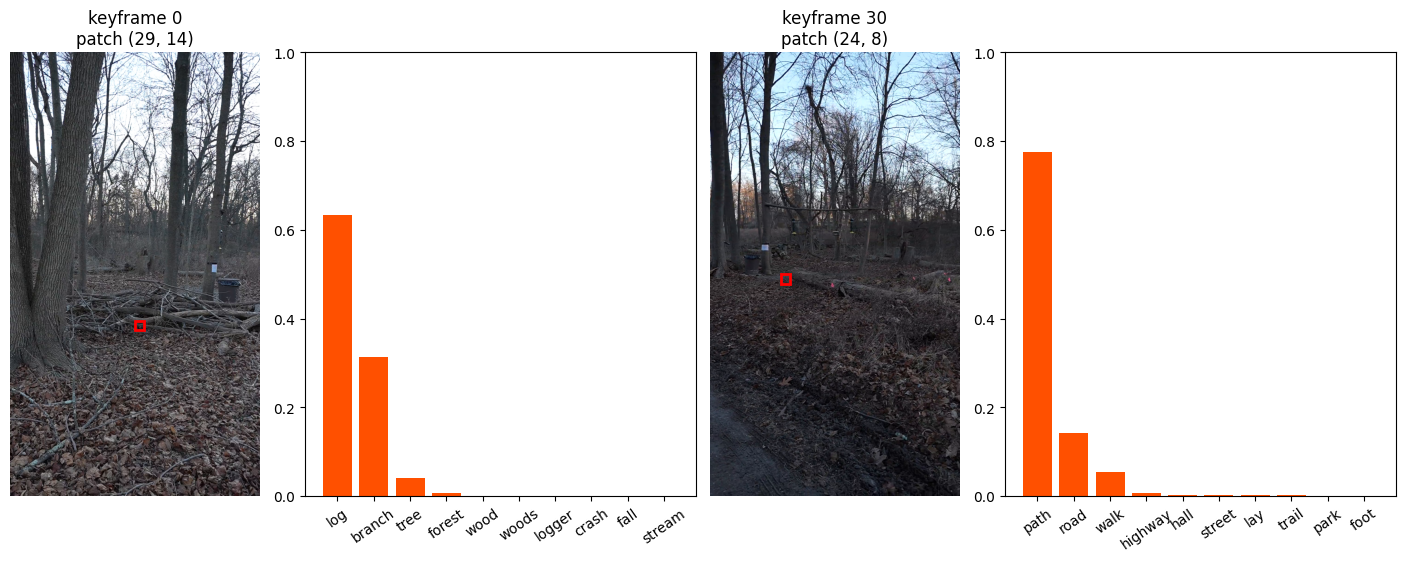

In [4]:
centers = []
fig, axes = plt.subplots(
    1, 4, figsize=(14, 5.5), width_ratios=[1, 1.5, 1, 1.5], layout="constrained"
)

for (keyframe, patch_row, patch_col), (labels, probs), (ax_frame, ax_bars) in zip(
    probes, patches, axes.reshape(2, 2)
):
    # The keyframe with the patch outlined; the patch grid spans the whole frame
    image = read_image(frame_paths(scene.images_dir)[rows[keyframe]])
    cell_w = image.shape[1] / width
    cell_h = image.shape[0] / height
    box = (patch_col * cell_w, patch_row * cell_h)
    ax_frame.imshow(image)
    ax_frame.add_patch(plt.Rectangle(box, cell_w, cell_h, fill=False, color="red", lw=2))
    centers.append(np.array([box[0] + cell_w / 2, box[1] + cell_h / 2, 1.0]))
    ax_frame.set(**BARE, title=f"keyframe {keyframe}\npatch ({patch_row}, {patch_col})")

    # The patch's words on the viewer's fixed 0-1 axis
    ax_bars.bar(labels, probs, color="#ff5000")
    ax_bars.set_ylim(0, 1)
    ax_bars.tick_params(axis="x", rotation=35)

A patch rarely reads as a single word. The brush-pile patch is mostly "log" with some "branch";
the patch on bare ground by the fallen log reads as "path", with "road" and "walk" behind it.
Lifting averages each vertex over every keyframe that saw it.

## 3. A vertex on the mesh

A ray from keyframe 0's camera through the brush-pile patch center finds the mesh vertex under
it, marked in red. The chart shows that vertex's lifted words, cut and rescaled as above:

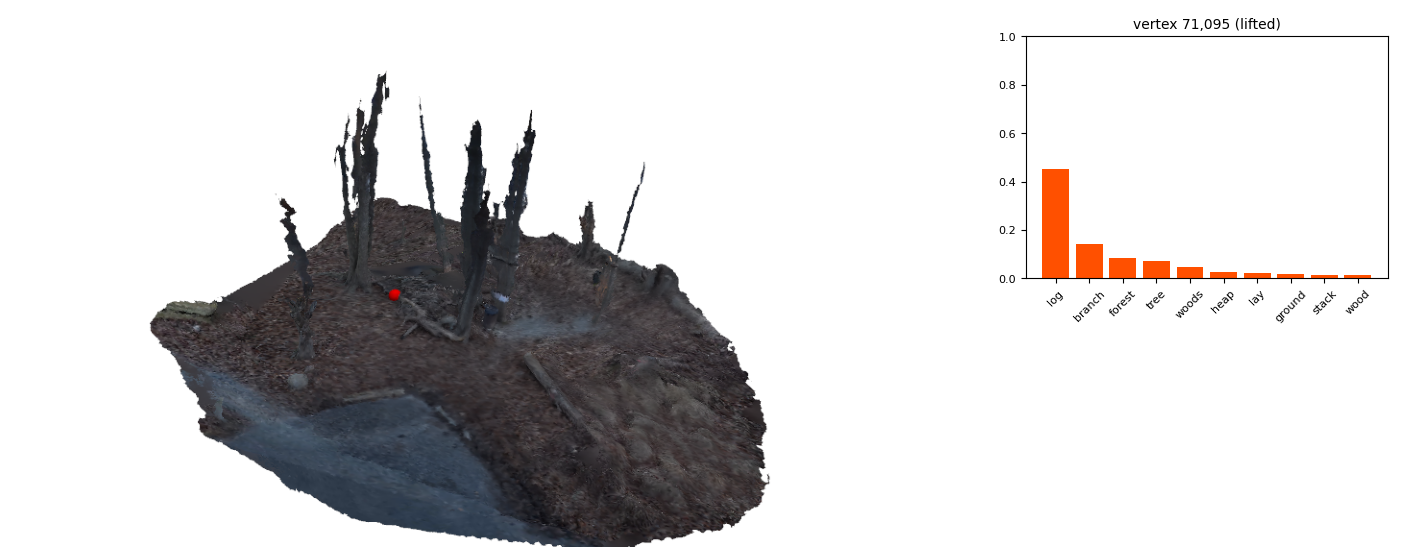

In [5]:
mesh = pv.read(scene.outputs["mesh"])
scene_size = np.ptp(mesh.points, axis=0).max()

# Ray from keyframe 0's camera through the brush-pile patch; the nearest vertex to the first hit
keyframe = probes[0][0]
cam_to_world = invert_poses(cloud.extrinsics)[keyframe]
ray = cam_to_world[:3, :3] @ np.linalg.inv(cloud.intrinsics[keyframe]) @ centers[0]
origin = cam_to_world[:3, 3]
far = origin + ray / np.linalg.norm(ray) * 10 * scene_size
hit, _ = mesh.ray_trace(origin, far, first_point=True)
vertex = mesh.find_closest_point(hit)

# The mesh in its own colors with the vertex marked, from behind the cameras
plotter = pv.Plotter(off_screen=True, window_size=(1000, 560))
plotter.add_mesh(mesh, scalars="RGB", rgb=True, lighting=False)
plotter.add_mesh(pv.Sphere(radius=0.01 * scene_size, center=mesh.points[vertex]), color="red")
apply_view(plotter, camera_view(cloud.extrinsics, mesh.points))
render = plotter.screenshot(return_img=True)
plotter.close()

fig, ax = plt.subplots(figsize=(14, 5.6), layout="constrained")
ax.imshow(render)
ax.set(**BARE)

# Blank margin right of the render holds the chart
ax.set_xlim(0, 1.45 * render.shape[1])

# The vertex's lifted words, inset top right on the viewer's fixed 0-1 axis
labels, probs = scene_words(word_ids[vertex], word_probs[vertex])
inset = ax.inset_axes([0.73, 0.5, 0.26, 0.45])
inset.bar(range(len(labels)), probs, color="#ff5000")
inset.set_xticks(range(len(labels)), labels)
inset.set_ylim(0, 1)
inset.set_title(f"vertex {vertex:,} (lifted)", fontsize=10)
inset.tick_params(axis="x", rotation=45, labelsize=8)
inset.tick_params(axis="y", labelsize=8)

Lifted words are softer than one patch's: each vertex averages every keyframe that saw it. The
patch read "log" 0.63 and "branch" 0.31; the vertex under it still reads mostly as "log", with
"branch", "forest" and "tree" behind it.

## In a pipeline run

The semantics stage does all of the above when `ocr_lens` is in its extractors:

```yaml
semantics:
  extractors: [ocr_lens]
```

The scene viewer serves the mesh with a word search and a click probe:

```bash
python -m collab_splats.viewer local data/tutorial_scene/vggt_omega --port 8080
```